In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


In [4]:
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")

In [6]:
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [8]:
print(df.shape)
print(df.info())
print(df.describe())

(6433, 14)
<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(

In [9]:
summary = pd.DataFrame({
    'Missing Count': df.isna().sum(),
    'Data Type': df.dtypes
})

cols_with_missing = summary['Missing Count'] > 0
print("Columns with missing values:")
print(summary[cols_with_missing])

Columns with missing values:
                 Missing Count Data Type
payment                     44       str
pickup_zone                 26       str
dropoff_zone                45       str
pickup_borough              26       str
dropoff_borough             45       str


#### checking for Duplicate


In [24]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
6428    False
6429    False
6430    False
6431    False
6432    False
Length: 6433, dtype: bool

In [22]:
print(df[df.duplicated()])

Empty DataFrame
Columns: [pickup, dropoff, passengers, distance, fare, tip, tolls, total, color, payment, pickup_zone, dropoff_zone, pickup_borough, dropoff_borough]
Index: []


#### Handling Missing Values

In [10]:
#Impute payment with mode
df["payment"] = df["payment"].fillna(df["payment"].mode()[0])

# Drop rows where pickup location is missing (since its used in visualizations)
df = df.dropna(subset=["pickup_borough", "pickup_zone"])

# Fill dropoff columns with 'Unknown'(since they are not used in visualizations dropping them would reduce the dataset size)
df["dropoff_zone"] = df["dropoff_zone"].fillna("Unknown")
df["dropoff_borough"] = df["dropoff_borough"].fillna("Unknown")

# Verify
print(df.isnull().sum())
print("Remaining rows:", len(df))

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64
Remaining rows: 6407


#### Visualization using matplotlib

In [10]:
plt.figure(figsize=(12, 5))

<Figure size 1200x500 with 0 Axes>

<Figure size 1200x500 with 0 Axes>

Line Chart

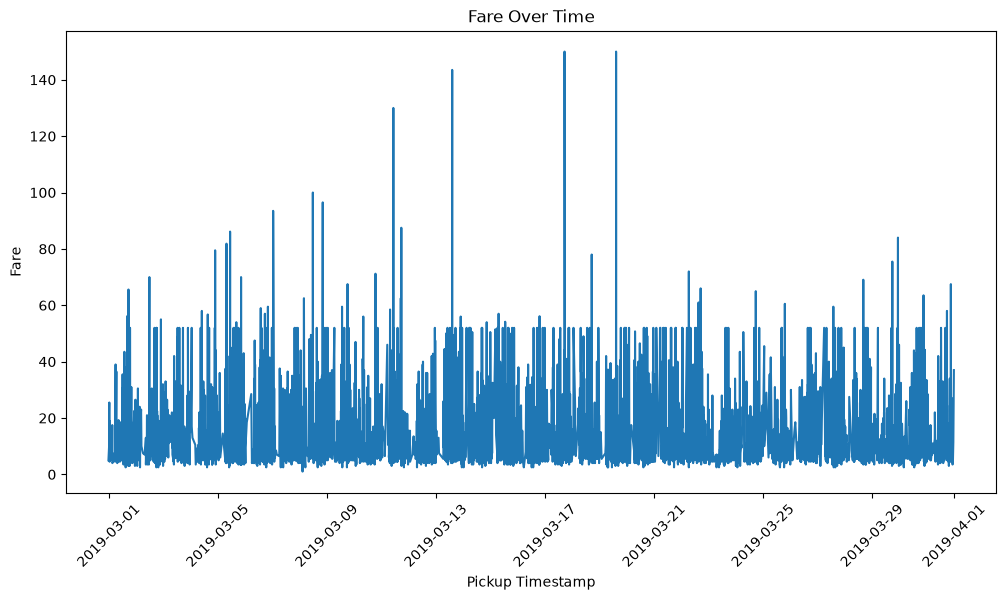

In [ ]:
# Convert pickup column into datetime format
df["pickup"] = pd.to_datetime(df["pickup"])

# Sort data according to pickup time
df_sorted = df.sort_values("pickup")

plt.plot(df_sorted["pickup"], df_sorted["fare"], label="Fare")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare")
plt.title("Fare Over Time")
plt.xticks(rotation=45)
plt.show()


Bar Chart

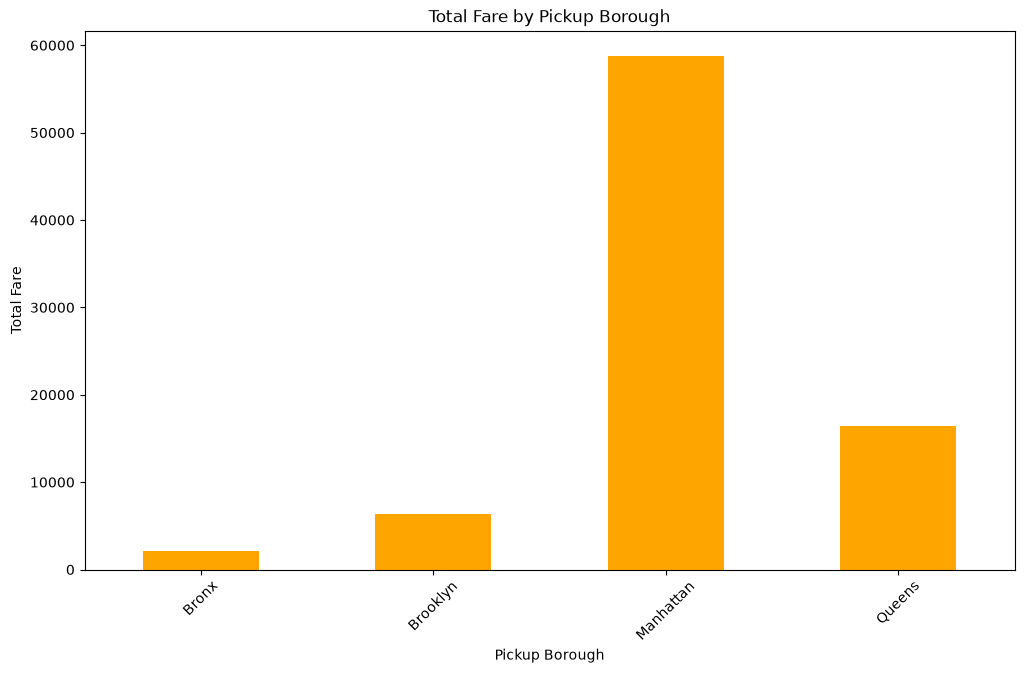

In [21]:
borough_fare = df.groupby('pickup_borough')['fare'].sum()
borough_fare.plot(
    kind='bar',
    figsize=(12, 7),
    color='orange'
)
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.title("Total Fare by Pickup Borough")

plt.xticks(rotation=45)
plt.show()

Pie Chart – Trips by Payment Method

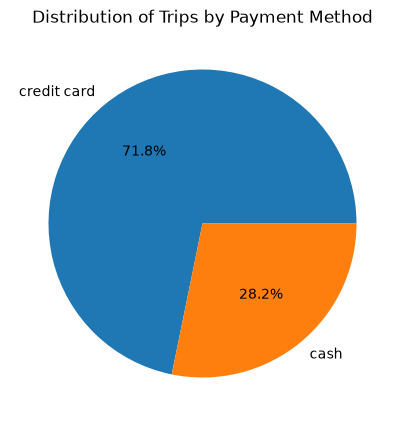

In [ ]:
payment_counts = df['payment'].value_counts()

plt.figure(figsize=(5, 5))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%'
)
plt.title('Distribution of Trips by Payment Method')
plt.show()

Histogram

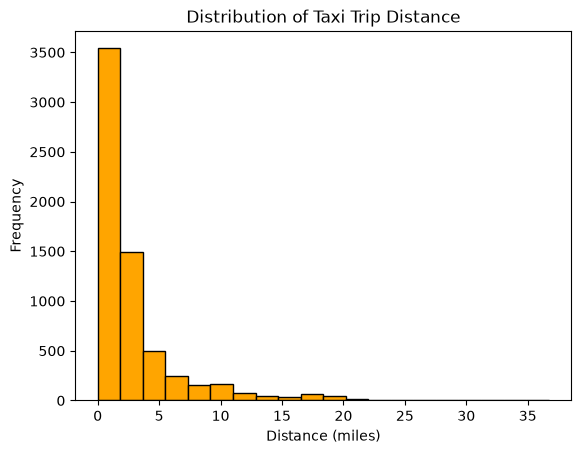

In [33]:

# Create the histogram
plt.hist(df['distance'], bins=20, color='orange', edgecolor='black')

plt.xlabel('Distance (miles)')
plt.ylabel('Frequency')
plt.title('Distribution of Taxi Trip Distance')

# Display the plot
plt.show()

Boxplot

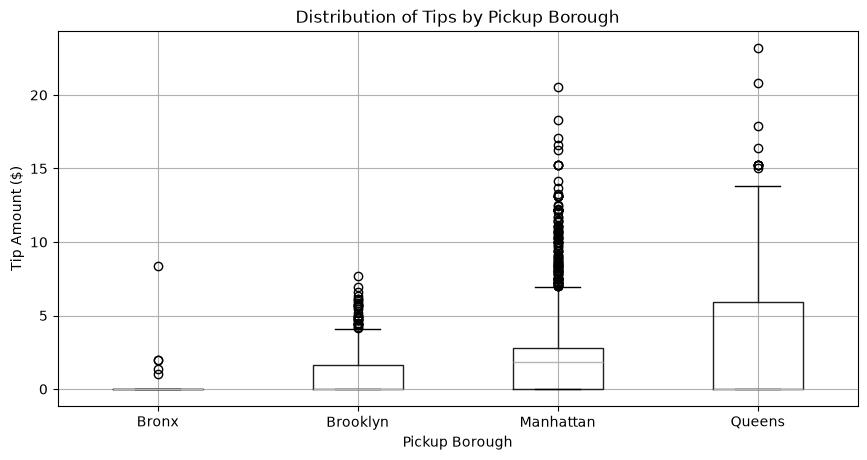

In [ ]:
df.boxplot(
    column='tip',
    by='pickup_borough',
    figsize=(10, 5)
)

plt.title('Distribution of Tips by Pickup Borough')
plt.suptitle('')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount ($)')
plt.show()

#### Visualizations Using Seaborn

★ Count Plot
Create a count plot to visualize the number of trips in each pickup_borough. The
x-axis should represent the boroughs, and the y-axis should show the count of trips.

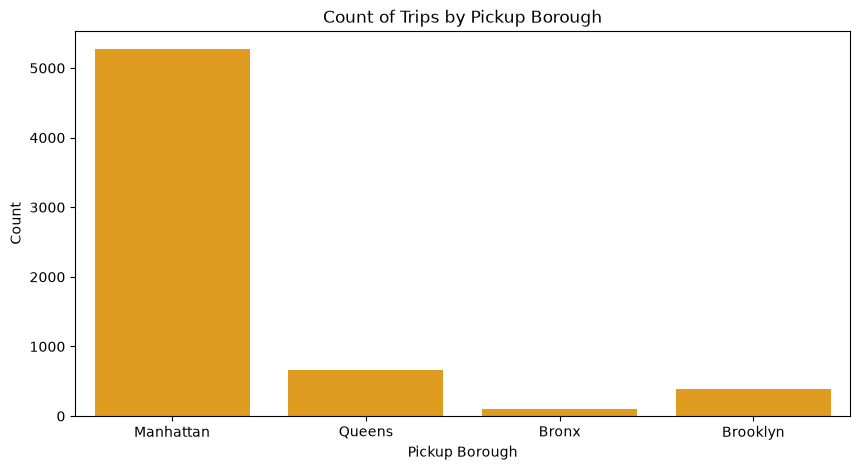

In [11]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,x='pickup_borough',color='orange')

plt.title('Count of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Count')
plt.show()


★ Scatter Plot
Plot a scatter plot to show the relationship between distance and fare. Use
distance on the x-axis and fare on the y-axis to visualize any correlation. Color the
points based on the pickup_borough to differentiate the trips by their respective
boroughs.


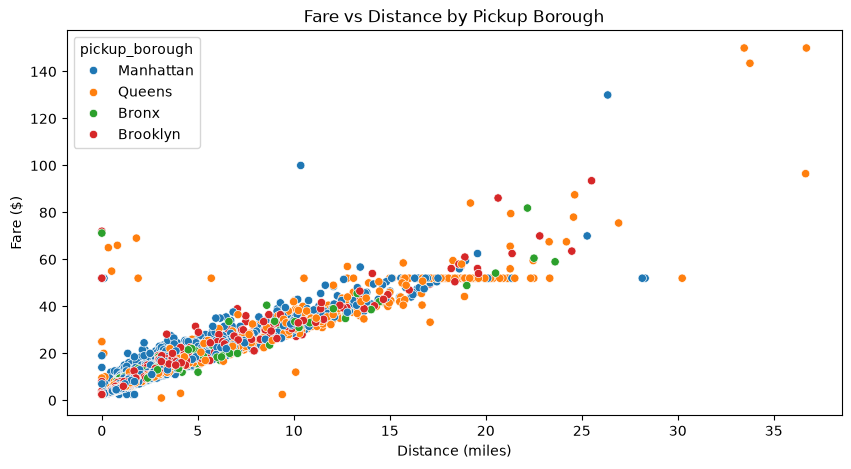

In [38]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df, x='distance', y='fare', hue='pickup_borough'
)
plt.title('Fare vs Distance by Pickup Borough')
plt.xlabel('Distance (miles)')
plt.ylabel('Fare ($)')
plt.show()


★ Heatmap
Plot a heatmap to visualize the correlation between numerical variables such as
distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the
relationships.


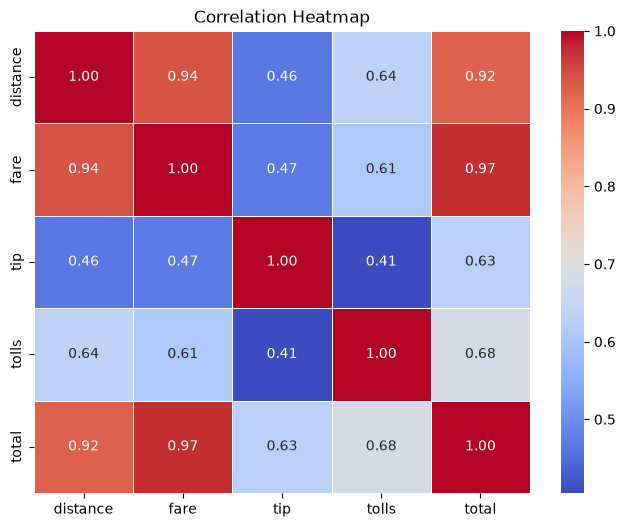

In [39]:

numeric_df= df[
    ['distance', 'fare', 'tip', 'tolls', 'total']
]


corr_matrix = numeric_df.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')

plt.show()


★ Pair Plot
Create a pair plot to visualize the pairwise relationships between distance, fare, tip,
and total. Color the data points according to the pickup_zone method to compare
how different zones affect these variables.


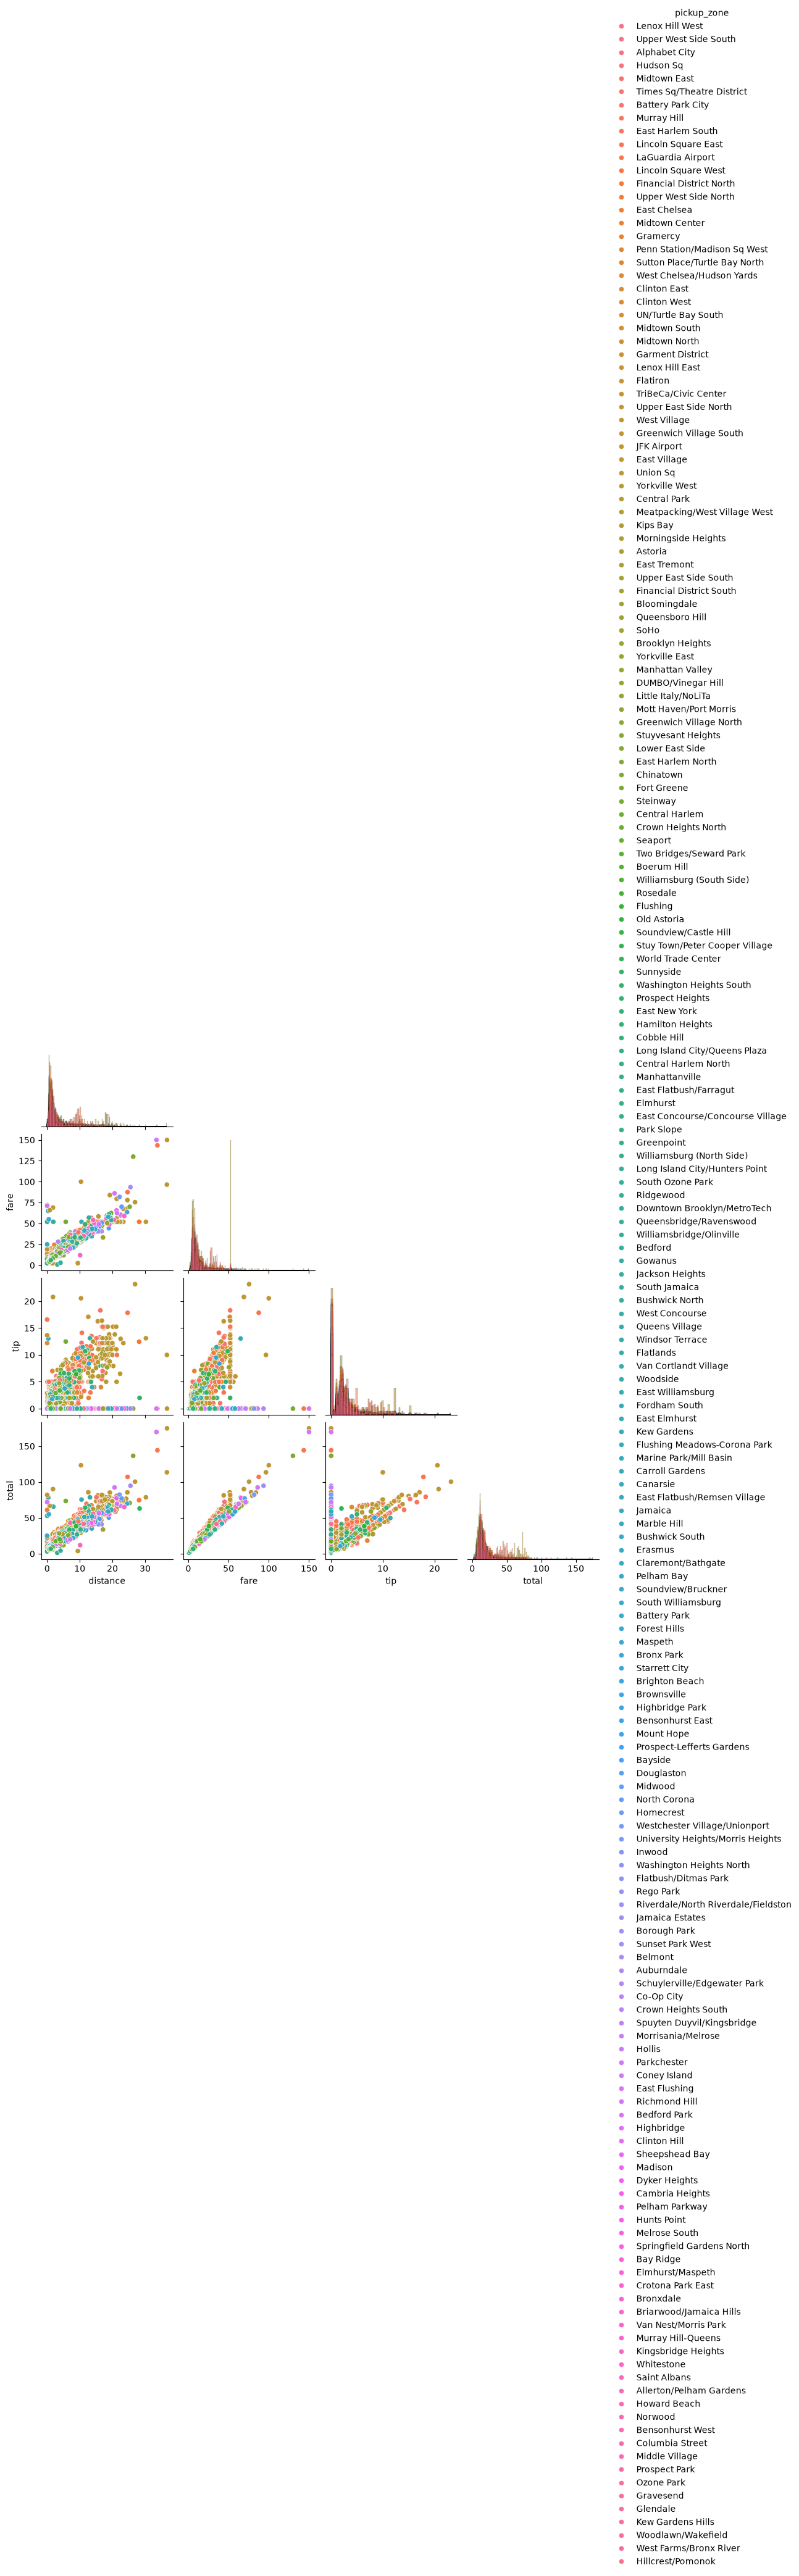

In [13]:

pair_data = df[
    ['distance', 'fare', 'tip', 'total', 'pickup_zone']
].dropna()

sns.pairplot(
    pair_data,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_zone',
    diag_kind='hist',
    corner=True
)

plt.show()


★ Violin Plot
Plot a violin plot to show the distribution of fare for each payment method. Use the
payment method as the categorical axis and fare as the numeric axis to visualize its
distribution.

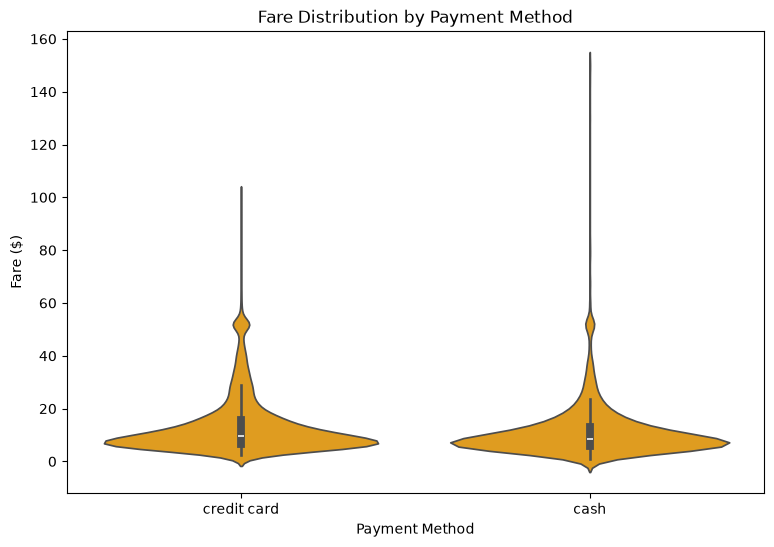

In [15]:
plt.figure(figsize=(9, 6))

sns.violinplot(
    data=df,
    x='payment',
    y='fare',
    color='orange'
)

plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare ($)')
plt.show()